In [1]:
#install xgboost
#import sys
#!{sys.executable} -m pip install xgboost

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
#import xgboost as xgb

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.inspection import permutation_importance
from xgboost import XGBRegressor

In [3]:
#load data set
waves= pd.read_csv(
    '/Users/gabrielagarcia/Desktop/Fall 2026/Geol 415/HW8/Waves_2023.txt',
    sep=r'\s+')
print(waves.head())
print(waves.columns)

     YY  MM  DD  hh  mm  WDIR  WSPD   GST  WVHT    DPD   APD  MWD    PRES  \
0  2023   1   1   0  26   999  99.0  99.0  1.12  12.50  7.69  269  9999.0   
1  2023   1   1   0  56   999  99.0  99.0  1.16  11.76  7.34  272  9999.0   
2  2023   1   1   1  26   999  99.0  99.0  1.20  12.50  7.08  268  9999.0   
3  2023   1   1   1  56   999  99.0  99.0  1.25  10.53  7.33  268  9999.0   
4  2023   1   1   2  26   999  99.0  99.0  1.27  10.53  7.57  268  9999.0   

    ATMP  WTMP   DEWP   VIS  TIDE  
0  999.0  15.3  999.0  99.0  99.0  
1  999.0  15.3  999.0  99.0  99.0  
2  999.0  15.3  999.0  99.0  99.0  
3  999.0  15.4  999.0  99.0  99.0  
4  999.0  15.5  999.0  99.0  99.0  
Index(['YY', 'MM', 'DD', 'hh', 'mm', 'WDIR', 'WSPD', 'GST', 'WVHT', 'DPD',
       'APD', 'MWD', 'PRES', 'ATMP', 'WTMP', 'DEWP', 'VIS', 'TIDE'],
      dtype='object')


In [4]:
# Remove the listed columns
waves = waves.drop(
    ['WDIR', 'WSPD', 'GST', 'PRES', 'ATMP', 'DEWP', 'VIS', 'TIDE'],
    axis=1
)

# Convert model variables to numbers
cols = ['WVHT', 'DPD', 'APD', 'MWD', 'WTMP']
waves[cols] = waves[cols].apply(pd.to_numeric, errors='coerce')

# Filter out bad data
waves = waves[waves['WVHT'] < 99]
waves = waves[waves['DPD'] < 99]
waves = waves[waves['APD'] < 99]
waves = waves[waves['MWD'] < 999]
waves = waves[waves['WTMP'] < 999]


In [5]:
#drop listed columns
wavesML = waves.drop(['YY','MM','DD','hh','mm'],axis = 1)

In [6]:
#create data set
df_X = wavesML.drop(['WVHT'],axis=1).to_numpy()
#create y value data set with just wave height
df_y = wavesML['WVHT'].to_numpy()

In [7]:
#split into test and train data
X_train, X_test, y_train, y_test = train_test_split(df_X, df_y, test_size=0.10)
#further split train data
X_train, X_val, y_train, y_val = train_test_split(X_train, y_train, test_size=0.10)

In [8]:
boost_reg_25 = XGBRegressor(
    objective='reg:squarederror',
    n_estimators=25,
    max_depth=3,
    learning_rate=0.1,
    random_state=42
)

linear_model = LinearRegression()

boost_reg_25.fit(X_train, y_train)
linear_model.fit(X_train, y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [9]:
# XGBoost predictions
boost_train = boost_reg_25.predict(X_train)
boost_val = boost_reg_25.predict(X_val)
boost_test = boost_reg_25.predict(X_test)
# Linear regression predictions
linear_train = linear_model.predict(X_train)
linear_val = linear_model.predict(X_val)
linear_test = linear_model.predict(X_test)

In [10]:
#XGBoost 
boost_train_mse = mean_squared_error(y_train, boost_train)
boost_train_r2 = r2_score(y_train, boost_train)

boost_val_mse = mean_squared_error(y_val, boost_val)
boost_val_r2 = r2_score(y_val, boost_val)

boost_test_mse = mean_squared_error(y_test, boost_test)
boost_test_r2 = r2_score(y_test, boost_test)

# Linear regression
linear_train_mse = mean_squared_error(y_train, linear_train)
linear_train_r2 = r2_score(y_train, linear_train)

linear_val_mse = mean_squared_error(y_val, linear_val)
linear_val_r2 = r2_score(y_val, linear_val)

linear_test_mse = mean_squared_error(y_test, linear_test)
linear_test_r2 = r2_score(y_test, linear_test)

In [11]:
print("XGBoost training MSE:", boost_train_mse)
print("XGBoost validation MSE:", boost_val_mse)
print("XGBoost test MSE:", boost_test_mse)
print("XGBoost training R²:", boost_train_r2)
print("XGBoost validation R²:", boost_val_r2)
print("XGBoost test R²:", boost_test_r2)
#print linear regression values
print("Linear regression training MSE:", linear_train_mse)
print("Linear regression MSE:", linear_val_mse)
print("Linear regression:", linear_test_mse)
print("Linear regression R²:", linear_train_r2)
print("Linear regression R²:", linear_val_r2)
print("Linear regression R²:", linear_test_r2)

XGBoost training MSE: 0.13186590660458633
XGBoost validation MSE: 0.11892183272805046
XGBoost test MSE: 0.1436574524663655
XGBoost training R²: 0.5250412781092155
XGBoost validation R²: 0.538036034107173
XGBoost test R²: 0.5091595537376779
Linear regression training MSE: 0.19630023041770808
Linear regression MSE: 0.17611180024283507
Linear regression: 0.20806013274937726
Linear regression R²: 0.29295972744771315
Linear regression R²: 0.3158757831562127
Linear regression R²: 0.2891122134299807


In [12]:
#1.  The MSE values are lower for the XGBoost model and the R2 values are higher,which implies the XGBoost
#model performed better.
#2. Cost function for linear regression is ordinary lease squares, which means it tries to minimize residual
#sum of squares between observed and predicted results.  Cost function for XGBoost also usses mean squareed error
# but it also penalizes tree complexity by adding penalties.

In [13]:
#3. No hyperparameters were optimized because data was fitted and model was trained without adjustments
#regardless of what MSE and R2 values were.

In [14]:
#Question 4
iterations = [2, 10, 25, 50, 100, 250, 500, 1000]

train_mse = []
val_mse = []

for n in iterations:
    model = XGBRegressor(
        objective='reg:squarederror',
        n_estimators=n,
        max_depth=3,
        learning_rate=0.1,
        random_state=42
    )

    model.fit(X_train, y_train)

    train_pred = model.predict(X_train)
    val_pred = model.predict(X_val)

    train_mse.append(mean_squared_error(y_train, train_pred))
    val_mse.append(mean_squared_error(y_val, val_pred))

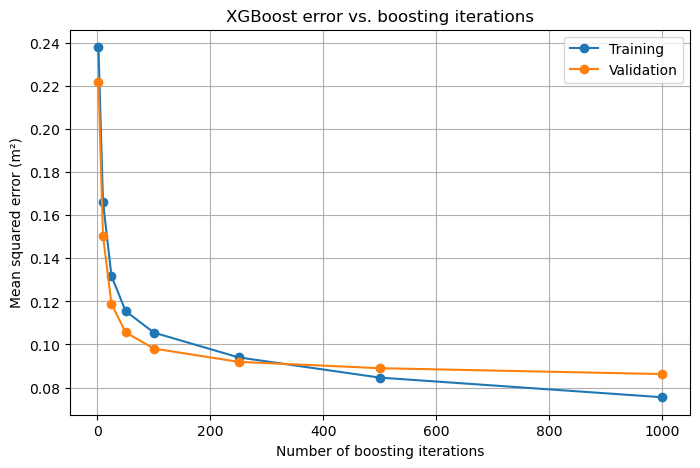

In [15]:
plt.figure(figsize=(8, 5))

plt.plot(iterations, train_mse, 'o-', label='Training')
plt.plot(iterations, val_mse, 'o-', label='Validation')

plt.xlabel('Number of boosting iterations')
plt.ylabel('Mean squared error (m²)')
plt.title('XGBoost error vs. boosting iterations')
plt.legend()
plt.grid(True)
plt.show()

In [16]:
#Question 5:  There is no significant evidence of overfitting.  Both the Training and 
#validation data show decreasing RMSE values as the number of iterations increases.  RMSE is 
#slightly lower for training data after about 250 iterations but both are still relatively low.

In [17]:
early_model = XGBRegressor(
    objective='reg:squarederror',
    n_estimators=1000,
    max_depth=3,
    learning_rate=0.1,
    eval_metric='rmse',
    early_stopping_rounds=10,
    random_state=42
)

early_model.fit(
    X_train,
    y_train,
    eval_set=[(X_val, y_val)],
    verbose=False
)
#determine what iteration was optimal
optimal_iterations = early_model.best_iteration + 1

print("Optimal boosting iterations:", optimal_iterations)
print("Best validation RMSE:", early_model.best_score)

Optimal boosting iterations: 288
Best validation RMSE: 0.3021028756570605


In [18]:
#Question 6: Based off the root mean squared error on the validation data, the optimal iteration 
#was 295.